In [ ]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *
import glob

In [16]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(0.25541281188299536, 0.5493061443340549)

In [3]:
dfs = [pd.read_csv(f) for f in glob.glob('../results/tmp/coal_time_ER_ising_d4_beta*.csv')]
df = pd.concat(dfs, ignore_index=True)
df

,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.26,F_beta_Glauber,False,full_star,25,10000000,100,25,8.050080e+03,5.680861e+03
1,0.26,F_beta_Glauber,False,full_star,25,10000000,500,24,4.974061e+05,1.024282e+06
2,0.26,F_beta_Glauber,False,full_star,25,10000000,1000,24,9.217710e+05,1.784088e+06
3,0.26,F_beta_Glauber,False,full_star,25,10000000,2500,17,2.591843e+06,2.026415e+06
4,0.26,F_beta_Glauber,False,full_star,25,10000000,5000,7,3.707875e+06,1.576705e+06
5,0.26,F_beta_Glauber,False,full_star,25,10000000,10000,0,NaN,NaN
6,0.26,F_beta_Glauber,False,full_star,25,10000000,25000,0,NaN,NaN
7,0.25,F_beta_Glauber,False,full_star,25,10000000,100,25,5.100120e+03,4.562086e+03
8,0.25,F_beta_Glauber,False,full_star,25,10000000,500,25,1.910865e+05,5.432993e+05
9,0.25,F_beta_Glauber,False,full_star,25,10000000,1000,25,2.209146e+05,1.424215e+05


# Scaling of coalescence times

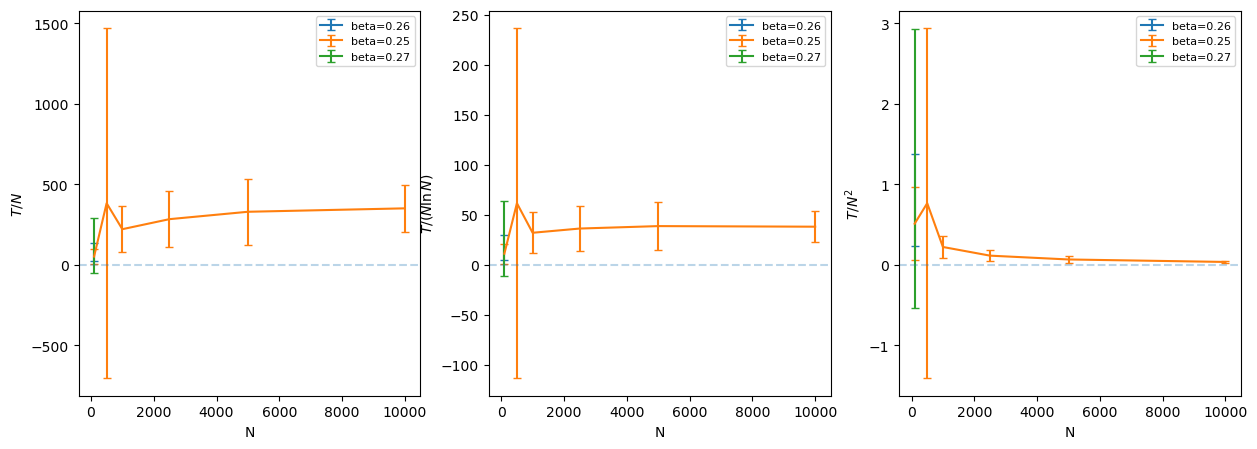

In [21]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['n_coal'] == df['n_runs']) &
    (df['init_mode'] == 'full_star') 
)
df_filtered = df[mask]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

betas_to_exclude = [0.23, 0.24, 0.22]
for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        if beta in betas_to_exclude:
            continue    
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.axhline(0, linestyle='--', alpha=0.3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.show()

# Proba of coalescence

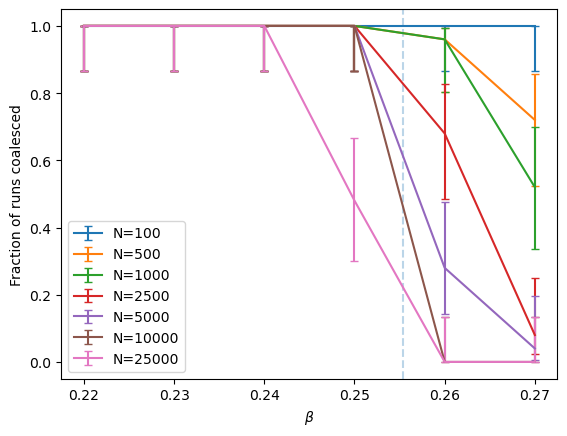

In [18]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['init_mode'] == 'full_star') 
)
df_filtered = df[mask]

N_to_exclude = []
for N in df_filtered['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.axvline(beta_uni, linestyle='--', alpha=0.3)
plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()